In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.ensemble import (
    RandomForestRegressor,
    RandomForestClassifier
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings("ignore")

In [33]:
df = pd.read_csv(r"C:\Users\SANKET THAKUR\PycharmProjects\PythonProject\Column_Chromatography_AI_ML\Data\Raw\rf_dataset_0203_total.csv")

In [34]:
print("Dataset Shape:", df.shape)

Dataset Shape: (22902, 10)


In [35]:
df.head(3)

,SMILES,Solvent_1,Solvent_2,Solvent_3,Fraction_1,Fraction_2,Fraction_3,Rf_value,doi,label
0,C(CCCCCCCCCCCCCCC)(=O)OCC(CO)O,Isohexane,Acetone,NaN,0.75,0.25,0.0,0.30,10.1007/s00216-024-05642-w,non-standard
1,N(=[N+]=[N-])CCCCCCCCC/C=C/CCCCC(=O)O,Ethyl acetate,Cyclohexane,NaN,0.50,0.50,0.0,0.10,10.1007/s00216-024-05642-w,non-standard
2,N(=[N+]=[N-])CCCCCCCCCCCCCCCC(=O)O,Ethyl acetate,Cyclohexane,NaN,0.50,0.50,0.0,0.15,10.1007/s00216-024-05642-w,non-standard


In [36]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 22902 entries, 0 to 22901
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   SMILES      22902 non-null  str    
 1   Solvent_1   22902 non-null  str    
 2   Solvent_2   20654 non-null  str    
 3   Solvent_3   298 non-null    str    
 4   Fraction_1  22902 non-null  float64
 5   Fraction_2  22902 non-null  float64
 6   Fraction_3  22902 non-null  float64
 7   Rf_value    22902 non-null  float64
 8   doi         22902 non-null  str    
 9   label       22902 non-null  str    
dtypes: float64(4), str(6)
memory usage: 3.9 MB


In [37]:
# Statistical summary
display(df.describe(include="all"))

,SMILES,Solvent_1,Solvent_2,Solvent_3,Fraction_1,Fraction_2,Fraction_3,Rf_value,doi,label
count,22902,22902,20654,298,22902.000000,22902.000000,22902.000000,22902.000000,22902,22902
unique,15735,19,21,16,NaN,NaN,NaN,NaN,1302,2
top,CC(C1=CC=C(N)C=C1)=O,Petroleum ether,Ethyl acetate,Ethyl acetate,NaN,NaN,NaN,NaN,10.1016/j.chempr.2022.08.008,non-standard
freq,31,7578,14559,100,NaN,NaN,NaN,NaN,4944,17958
mean,NaN,NaN,NaN,NaN,0.825393,0.173872,0.000735,0.453428,NaN,NaN
std,NaN,NaN,NaN,NaN,0.158830,0.158120,0.010393,0.236128,NaN,NaN
min,NaN,NaN,NaN,NaN,0.334000,0.000000,0.000000,-0.013000,NaN,NaN
25%,NaN,NaN,NaN,NaN,0.750000,0.048000,0.000000,0.300000,NaN,NaN
50%,NaN,NaN,NaN,NaN,0.900000,0.100000,0.000000,0.400000,NaN,NaN
75%,NaN,NaN,NaN,NaN,0.952000,0.250000,0.000000,0.598000,NaN,NaN


In [38]:
# Dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 22902 entries, 0 to 22901
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   SMILES      22902 non-null  str    
 1   Solvent_1   22902 non-null  str    
 2   Solvent_2   20654 non-null  str    
 3   Solvent_3   298 non-null    str    
 4   Fraction_1  22902 non-null  float64
 5   Fraction_2  22902 non-null  float64
 6   Fraction_3  22902 non-null  float64
 7   Rf_value    22902 non-null  float64
 8   doi         22902 non-null  str    
 9   label       22902 non-null  str    
dtypes: float64(4), str(6)
memory usage: 3.9 MB


In [39]:
# Number of unique values
df.nunique()

SMILES        15735
Solvent_1        19
Solvent_2        21
Solvent_3        16
Fraction_1      139
Fraction_2      126
Fraction_3       47
Rf_value        969
doi            1302
label             2
dtype: int64

In [40]:
# Statistical summary
display(df.describe(include="all"))

,SMILES,Solvent_1,Solvent_2,Solvent_3,Fraction_1,Fraction_2,Fraction_3,Rf_value,doi,label
count,22902,22902,20654,298,22902.000000,22902.000000,22902.000000,22902.000000,22902,22902
unique,15735,19,21,16,NaN,NaN,NaN,NaN,1302,2
top,CC(C1=CC=C(N)C=C1)=O,Petroleum ether,Ethyl acetate,Ethyl acetate,NaN,NaN,NaN,NaN,10.1016/j.chempr.2022.08.008,non-standard
freq,31,7578,14559,100,NaN,NaN,NaN,NaN,4944,17958
mean,NaN,NaN,NaN,NaN,0.825393,0.173872,0.000735,0.453428,NaN,NaN
std,NaN,NaN,NaN,NaN,0.158830,0.158120,0.010393,0.236128,NaN,NaN
min,NaN,NaN,NaN,NaN,0.334000,0.000000,0.000000,-0.013000,NaN,NaN
25%,NaN,NaN,NaN,NaN,0.750000,0.048000,0.000000,0.300000,NaN,NaN
50%,NaN,NaN,NaN,NaN,0.900000,0.100000,0.000000,0.400000,NaN,NaN
75%,NaN,NaN,NaN,NaN,0.952000,0.250000,0.000000,0.598000,NaN,NaN


In [41]:
# Convert infinite values to NaN
df.replace([np.inf, -np.inf], np.nan, inplace=True)

,SMILES,Solvent_1,Solvent_2,Solvent_3,Fraction_1,Fraction_2,Fraction_3,Rf_value,doi,label
0,C(CCCCCCCCCCCCCCC)(=O)OCC(CO)O,Isohexane,Acetone,NaN,0.750,0.250,0.0,0.300,10.1007/s00216-024-05642-w,non-standard
1,N(=[N+]=[N-])CCCCCCCCC/C=C/CCCCC(=O)O,Ethyl acetate,Cyclohexane,NaN,0.500,0.500,0.0,0.100,10.1007/s00216-024-05642-w,non-standard
2,N(=[N+]=[N-])CCCCCCCCCCCCCCCC(=O)O,Ethyl acetate,Cyclohexane,NaN,0.500,0.500,0.0,0.150,10.1007/s00216-024-05642-w,non-standard
3,N(=[N+]=[N-])CCCCCCCCCC=CCCCCC(=O)OCC(COC(CCCC...,Ethyl acetate,Isohexane,NaN,0.500,0.500,0.0,0.780,10.1007/s00216-024-05642-w,non-standard
4,N(=[N+]=[N-])CCCCCCCCCCCCCCCC(=O)OCC(COC(CCCCC...,Ethyl acetate,Isohexane,NaN,0.500,0.500,0.0,0.670,10.1007/s00216-024-05642-w,non-standard
...,...,...,...,...,...,...,...,...,...,...
22897,O=C1CCC(C)C2=C1C=CC=C2,Water,Diethyl ether,NaN,0.500,0.500,0.0,0.662,10.1016/j.chempr.2022.08.008,standard
22898,O=C1CCC(C)C2=C1C=CC=C2,Diethyl ether,NaN,NaN,1.000,0.000,0.0,0.989,10.1016/j.chempr.2022.08.008,standard
22899,O=C1CCCC2=C1N=CC=C2,Water,Diethyl ether,NaN,0.667,0.333,0.0,0.000,10.1016/j.chempr.2022.08.008,standard
22900,O=C1CCCC2=C1N=CC=C2,Water,Diethyl ether,NaN,0.500,0.500,0.0,0.011,10.1016/j.chempr.2022.08.008,standard


In [42]:
# Missing value count
missing = df.isnull().sum()
print("Missing Values:")
print(missing[missing > 0])

Missing Values:
Solvent_2     2248
Solvent_3    22604
dtype: int64


In [43]:
# Missing value percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100
print("\nMissing Percentage:")
print(missing_percentage[missing_percentage > 0])


Missing Percentage:
Solvent_2     9.815737
Solvent_3    98.698804
dtype: float64


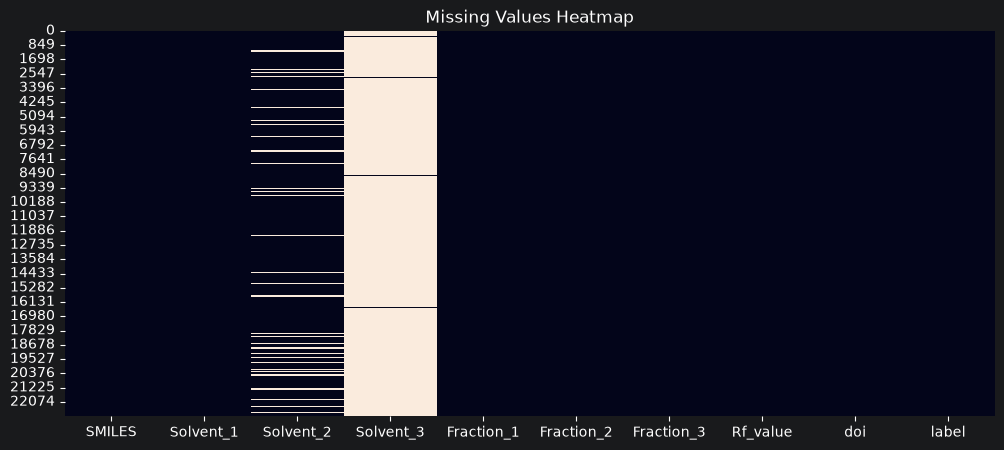

In [44]:
# Visualize missing values
plt.figure(figsize=(12, 5))
sns.heatmap(df.isnull(), cbar=False)
plt.title("Missing Values Heatmap")
plt.show()

In [45]:
print("Duplicates:", df.duplicated().sum())

Duplicates: 1717


In [46]:
df.drop_duplicates(inplace=True)

print("Shape after duplicate removal:", df.shape)

Shape after duplicate removal: (21185, 10)


In [47]:
print(df["Fraction_3"].isnull().sum())
print(df["Fraction_3"].value_counts(dropna=False))

0
Fraction_3
0.000    20918
0.010       39
0.071       28
0.005       21
0.100       17
0.050       17
0.001       14
0.020       14
0.083       13
0.002       12
0.200       10
0.029        9
0.333        7
0.042        5
0.167        4
0.037        4
0.077        4
0.048        4
0.045        3
0.025        3
0.003        3
0.125        3
0.016        3
0.012        2
0.006        2
0.009        2
0.019        2
0.250        2
0.150        2
0.059        1
0.133        1
0.007        1
0.027        1
0.008        1
0.004        1
0.015        1
0.300        1
0.091        1
0.130        1
0.030        1
0.062        1
0.032        1
0.024        1
0.023        1
0.038        1
0.011        1
0.040        1
Name: count, dtype: int64


In [48]:
# Remove unnecessary columns
df = df.drop(columns=["Solvent_3", "Fraction_3", "doi", "label"])

# Remove incomplete target records
df = df.dropna(subset=[
    "SMILES", "Solvent_1", "Solvent_2",
    "Fraction_1", "Fraction_2"
]).copy()

In [49]:
# Create solvent combination target
def create_solvent_system(row):

    components = [
        (row["Solvent_1"], row["Fraction_1"]),
        (row["Solvent_2"], row["Fraction_2"])
    ]

    components.sort(key=lambda x: x[0])

    return " + ".join(
        f"{solvent} ({fraction:.2f})"
        for solvent, fraction in components
    )

df["Solvent_System"] = df.apply(
    create_solvent_system, axis=1
)

print(df["Solvent_System"].value_counts().head(10))

Solvent_System
Ethyl acetate (0.09) + Petroleum ether (0.91)    1131
Ethyl acetate (0.50) + Hexane (0.50)              827
Ethyl acetate (0.20) + Hexane (0.80)              767
Ethyl acetate (0.17) + Petroleum ether (0.83)     767
Ethyl acetate (0.50) + Petroleum ether (0.50)     640
Ethyl acetate (0.10) + Hexane (0.90)              636
Ethyl acetate (0.20) + Petroleum ether (0.80)     583
Ethyl acetate (0.05) + Petroleum ether (0.95)     569
Ethyl acetate (0.33) + Petroleum ether (0.67)     450
Ethyl acetate (0.05) + Hexane (0.95)              439
Name: count, dtype: int64


In [50]:
from rdkit import Chem
from rdkit.Chem import Descriptors, rdMolDescriptors

def calculate_descriptors(smiles):

    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    return {
        "MolWt": Descriptors.MolWt(mol),
        "LogP": Descriptors.MolLogP(mol),
        "TPSA": Descriptors.TPSA(mol),
        "HBD": Descriptors.NumHDonors(mol),
        "HBA": Descriptors.NumHAcceptors(mol),
        "RotatableBonds": Descriptors.NumRotatableBonds(mol),
        "AromaticRings": rdMolDescriptors.CalcNumAromaticRings(mol),
        "FractionCSP3": rdMolDescriptors.CalcFractionCSP3(mol)
    }

In [51]:
features = df["SMILES"].apply(calculate_descriptors)

valid = features.notna()

df = df.loc[valid].copy()

In [52]:
X = pd.DataFrame(
    features.loc[valid].tolist(),
    index=df.index
)

y = df["Solvent_System"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (19021, 8)
Target shape: (19021,)


In [53]:
print("Unique solvent systems:", y.nunique())

print("\nMost common solvent systems:")
print(y.value_counts().head(15))

Unique solvent systems: 667

Most common solvent systems:
Solvent_System
Ethyl acetate (0.09) + Petroleum ether (0.91)    1131
Ethyl acetate (0.50) + Hexane (0.50)              827
Ethyl acetate (0.20) + Hexane (0.80)              767
Ethyl acetate (0.17) + Petroleum ether (0.83)     767
Ethyl acetate (0.50) + Petroleum ether (0.50)     640
Ethyl acetate (0.10) + Hexane (0.90)              636
Ethyl acetate (0.20) + Petroleum ether (0.80)     583
Ethyl acetate (0.05) + Petroleum ether (0.95)     569
Ethyl acetate (0.33) + Petroleum ether (0.67)     450
Ethyl acetate (0.05) + Hexane (0.95)              439
Dichloromethane (0.95) + Methanol (0.05)          439
Ethyl acetate (0.25) + Petroleum ether (0.75)     427
Dichloromethane (0.91) + Methanol (0.09)          408
Dichloromethane (0.98) + Methanol (0.02)          402
Dichloromethane (0.97) + Methanol (0.03)          371
Name: count, dtype: int64


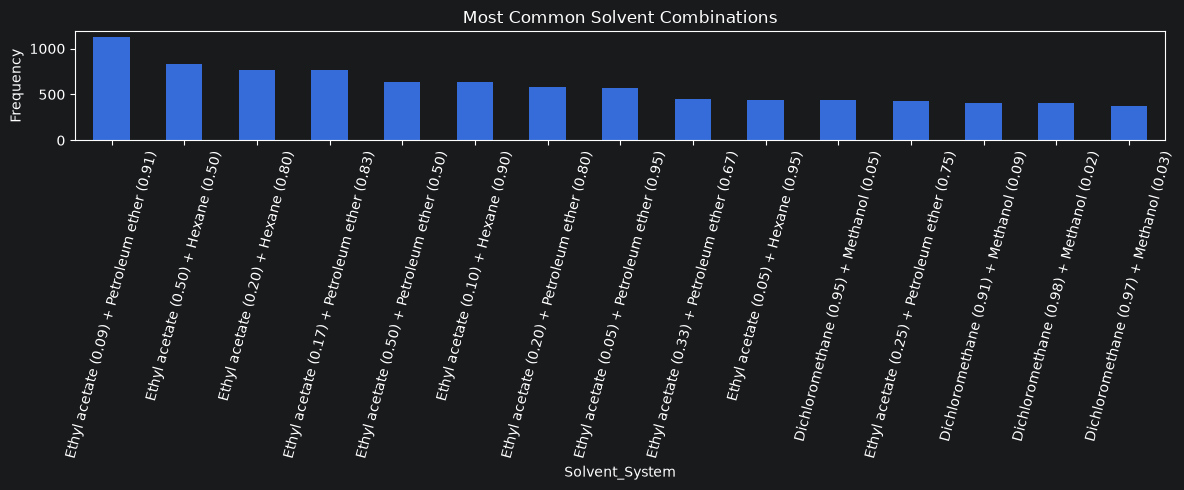

In [54]:
plt.figure(figsize=(12, 5))

y.value_counts().head(15).plot(kind="bar")

plt.title("Most Common Solvent Combinations")
plt.ylabel("Frequency")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

In [55]:
print("Total records:", len(y))
print("Unique classes:", y.nunique())
print("\nClass distribution:")
print(y.value_counts().value_counts().sort_index())
print("\nClasses with fewer than 2 records:")
print(y.value_counts()[y.value_counts() < 2])

Total records: 19021
Unique classes: 667

Class distribution:
count
1       238
2        86
3        58
4        38
5        25
       ... 
636       1
640       1
767       2
827       1
1131      1
Name: count, Length: 90, dtype: int64

Classes with fewer than 2 records:
Solvent_System
Acetone (0.25) + Isohexane (0.75)                1
Ethyl acetate (0.28) + Hexane (0.72)             1
Pentane (0.60) + Toluene (0.40)                  1
Hexane (0.99) + MTBE (0.01)                      1
Ethyl acetate (0.91) + i-PrOH (0.09)             1
                                                ..
Dichloromethane (0.50) + Hexane (0.30)           1
Acetonitrile (0.60) + Water (0.40)               1
Dichloromethane (0.40) + Hexane (0.45)           1
Dichloromethane (0.15) + Hexane (0.85)           1
Ethyl acetate (0.13) + Petroleum ether (0.87)    1
Name: count, Length: 238, dtype: int64


In [56]:
from sklearn.model_selection import train_test_split

# Remove classes having fewer than 2 observations
class_counts = y.value_counts()

valid_classes = class_counts[class_counts >= 2].index

mask = y.isin(valid_classes)

X_clean = X.loc[mask]
y_clean = y.loc[mask]

X_train, X_test, y_train, y_test = train_test_split(
    X_clean,
    y_clean,
    test_size=0.20,
    random_state=42,
    stratify=y_clean
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (15026, 8)
Testing: (3757, 8)


In [57]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=150,        # Reduced from 300 to 150 to cut forest size in half
        max_depth=15,            # Stops trees from growing infinitely deep
        min_samples_leaf=4,      # Ensures leaf nodes hold a reasonable sample size
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])


model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [58]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    balanced_accuracy_score
)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("Precision:", precision_score(
    y_test, y_pred,
    average="weighted",
    zero_division=0
))

print("Recall:", recall_score(
    y_test, y_pred,
    average="weighted",
    zero_division=0
))

print("F1 Score:", f1_score(
    y_test, y_pred,
    average="weighted",
    zero_division=0
))

print("Balanced Accuracy:", balanced_accuracy_score(
    y_test, y_pred
))

print(classification_report(
    y_test, y_pred,
    zero_division=0
))

Accuracy: 0.04391801969656641
Precision: 0.0512958860184665
Recall: 0.04391801969656641
F1 Score: 0.02727471025594315
Balanced Accuracy: 0.23755621605475832
                                                 precision    recall  f1-score   support

        Acetone (0.00) + Dichloromethane (1.00)       0.00      0.00      0.00         0
                 Acetone (0.02) + Hexane (0.98)       0.00      0.00      0.00         1
        Acetone (0.03) + Petroleum ether (0.97)       0.33      1.00      0.50         1
        Acetone (0.04) + Dichloromethane (0.96)       0.00      0.00      0.00         0
        Acetone (0.05) + Dichloromethane (0.95)       0.00      0.00      0.00         2
                 Acetone (0.05) + Hexane (0.95)       0.12      0.17      0.14         6
        Acetone (0.05) + Petroleum ether (0.95)       0.00      0.00      0.00         1
        Acetone (0.09) + Dichloromethane (0.91)       0.00      0.00      0.00         1
        Acetone (0.09) + Petroleum ether 

In [63]:
# Select one sample from the test dataset
sample_index = X_test.index[0]

# Extract molecular descriptors as an array
sample_array = X_test.loc[sample_index].values.reshape(1, -1)

print("Input Array:")
print(sample_array)

# Predict solvent system
prediction = model.predict(sample_array)

print("\nPredicted Solvent System:", prediction[0])

print("Actual Solvent System:", y_test.loc[sample_index])

Input Array:
[[2.3627e+02 2.7815e+00 2.6300e+01 0.0000e+00 2.0000e+00 2.0000e+00
  2.0000e+00 6.2500e-02]]

Predicted Solvent System: Acetone (0.00) + Dichloromethane (1.00)
Actual Solvent System: Ethyl acetate (0.10) + Hexane (0.90)


In [64]:
# Fetch the actual SMILES string for this specific sample index
smiles = df.loc[sample_index, "SMILES"]

print("=" * 45)
print("CHROMATOGRAPHY SOLVENT PREDICTION")
print("=" * 45)

print("SMILES:", smiles)
print("Actual Solvent System:", y_test.loc[sample_index])
print("Predicted Solvent System:", prediction[0])

print("=" * 45)

CHROMATOGRAPHY SOLVENT PREDICTION
SMILES: C1(=CC=CC=C1)C#CC(=O)OCC1=CC=CC=C1
Actual Solvent System: Ethyl acetate (0.10) + Hexane (0.90)
Predicted Solvent System: Acetone (0.00) + Dichloromethane (1.00)


In [65]:
import joblib

# Compress level 3 offers a great performance and size balance
joblib.dump(model, r"C:\Users\SANKET THAKUR\PycharmProjects\PythonProject\Column_Chromatography_AI_ML\Model\chromatography_model.joblib", compress=3)


['C:\\Users\\SANKET THAKUR\\PycharmProjects\\PythonProject\\Column_Chromatography_AI_ML\\Model\\chromatography_model.joblib']